In [1]:
import pandas as pd
import xarray as xr

time = ("2011-12", "2011-12")

observation_data = (
    xr.open_dataset("inputs/JohanBuoys/processed/JohanBuoys_netherlands.nc")
    .sel(time=slice(time[0], time[1]))
    .resample(time="1H")
    .mean()
)
metamodel_data = (
    xr.open_dataset("outputs/201112_500_spectra_WHACS.nc")
    .sel(time=slice(time[0], time[1]))["__xarray_dataarray_variable__"]
    .spec.stats(["hs", "tm01", "dm"])
)
dynamic_data = xr.open_dataset("outputs/Dynamic_Cases_201106_201112.nc").sel(
    time=slice(time[0], time[1])
)
era5_data = xr.open_zarr("inputs/ERA5/processed/ERA5_netherlands.zarr").sel(
    time=slice(time[0], time[1])
)[["swh", "mwp", "mwd"]]
whacs_data = xr.open_zarr("inputs/WHACS/processed/WHACS_netherlands.zarr").sel(
    time=slice(time[0], time[1])
)[["hs", "t01", "dir"]]
codec_data = xr.open_zarr("inputs/CODEC/processed/CODEC_netherlands.zarr").sel(
    time=slice(time[0], time[1])
)

buoys_coords = pd.read_csv("inputs/JohanBuoys/JohanBuoys_coordinates.csv")
goals_coords = pd.read_csv("inputs/WHACS/WHACS_coordinates.csv")
codec_coords = pd.read_csv("inputs/CODEC/CODEC_coordinates.csv")

BATHY_PATH = "inputs/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.nc"

/home/tausiaj/miniforge3/envs/bluemath-311-dev/lib/python3.11/site-packages/xarray/groupers.py:530: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  self.index_grouper = pd.Grouper(


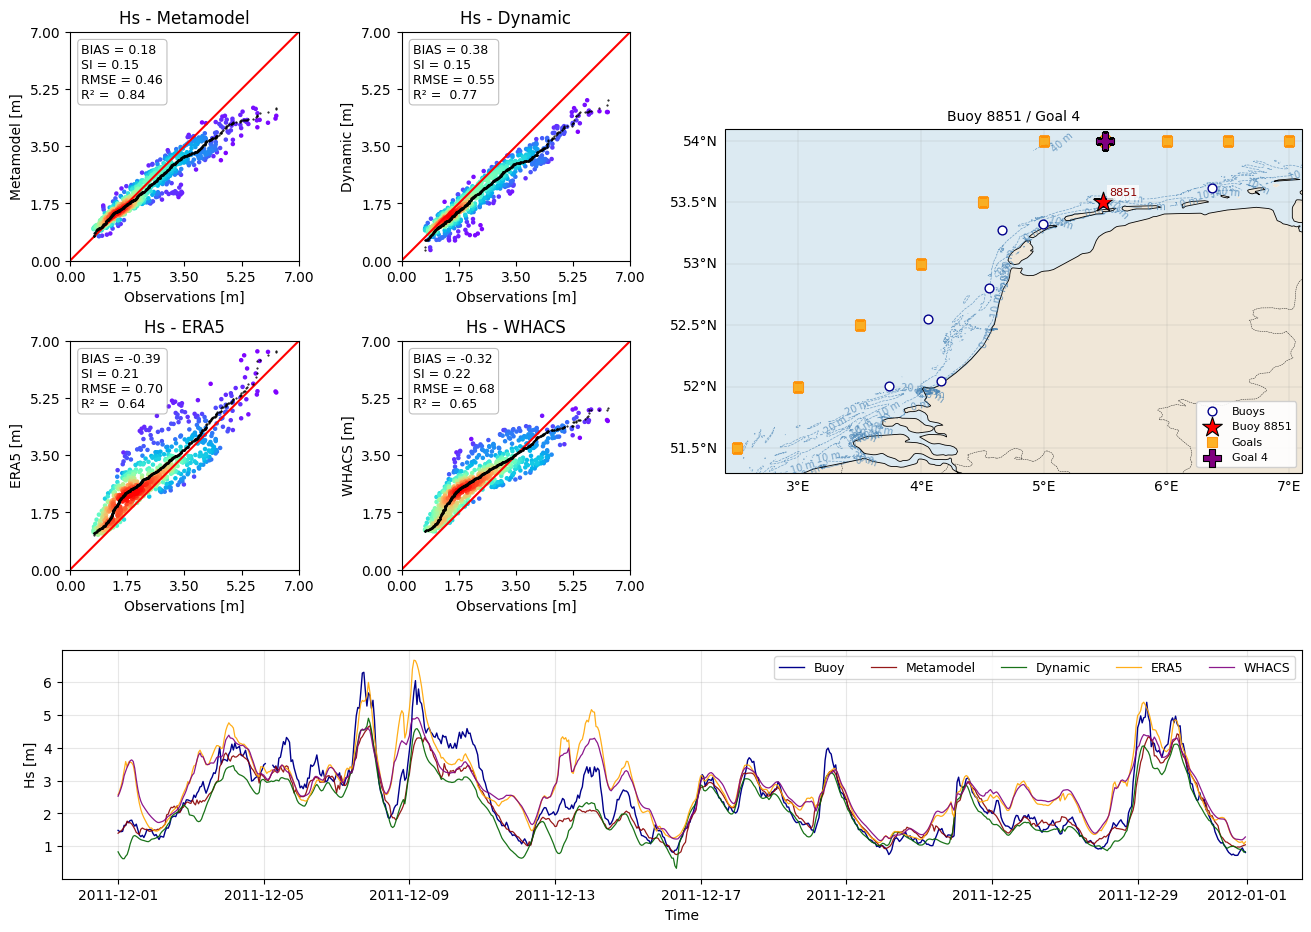

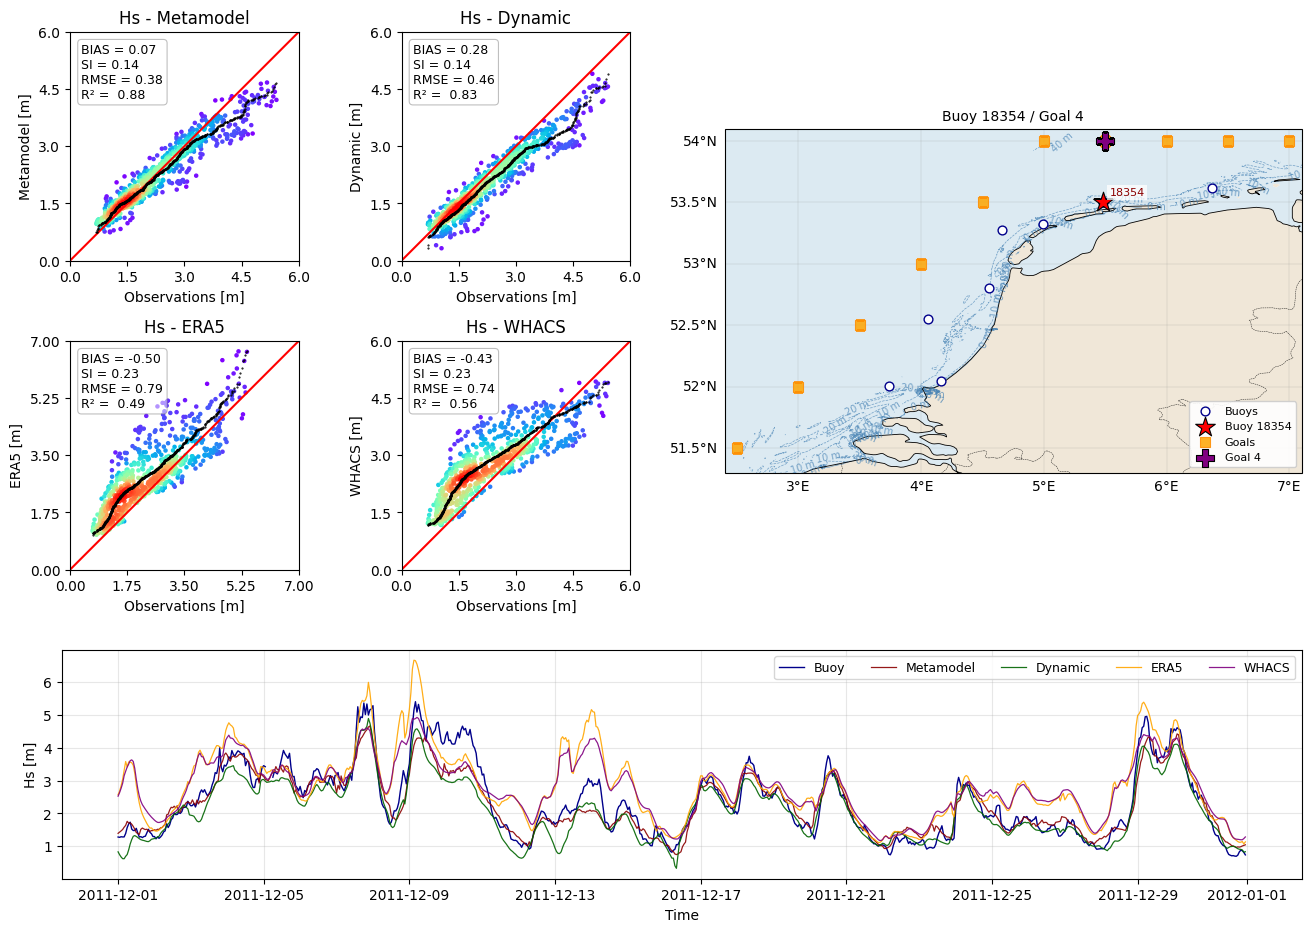

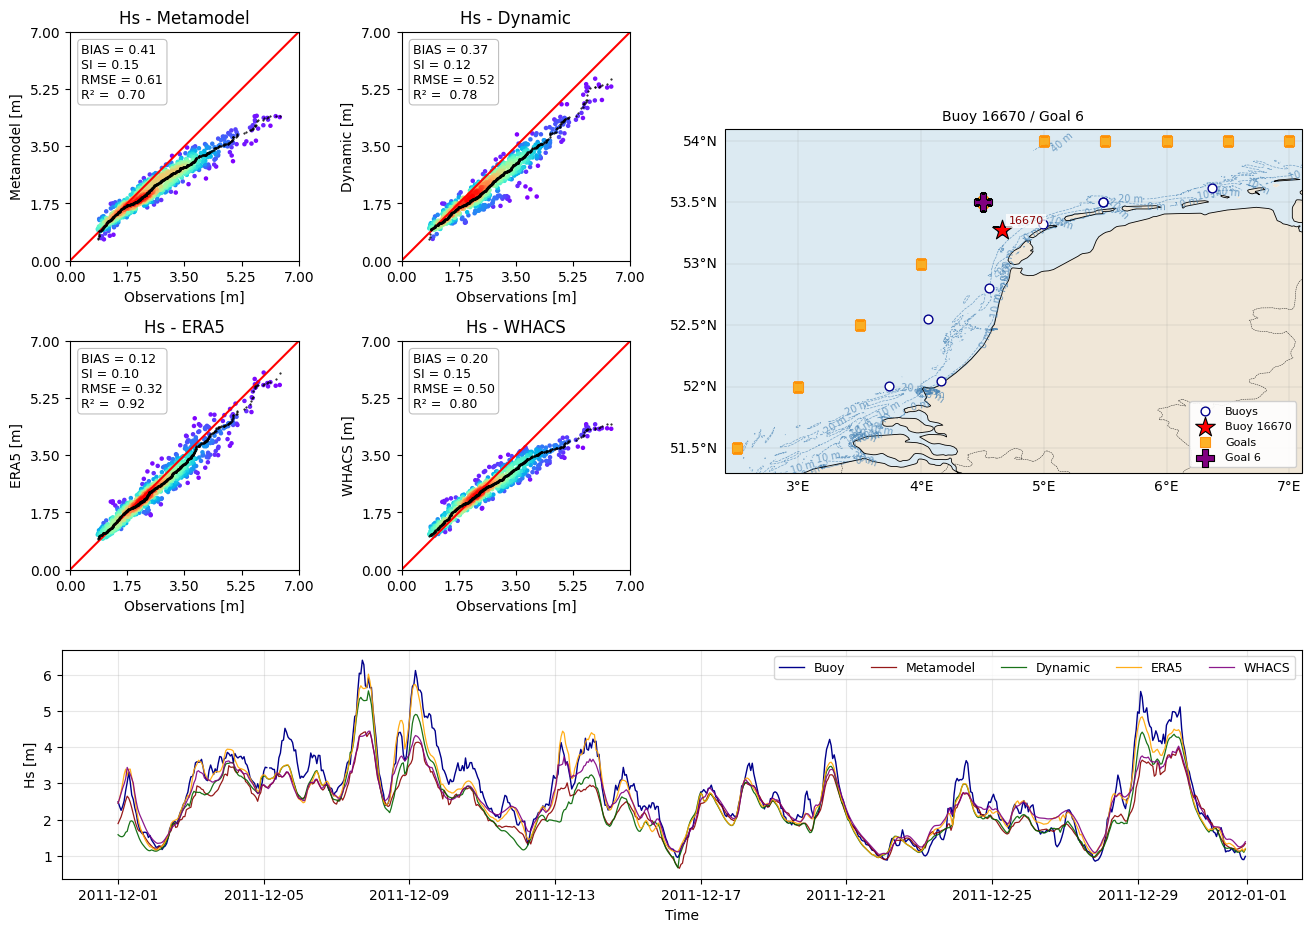

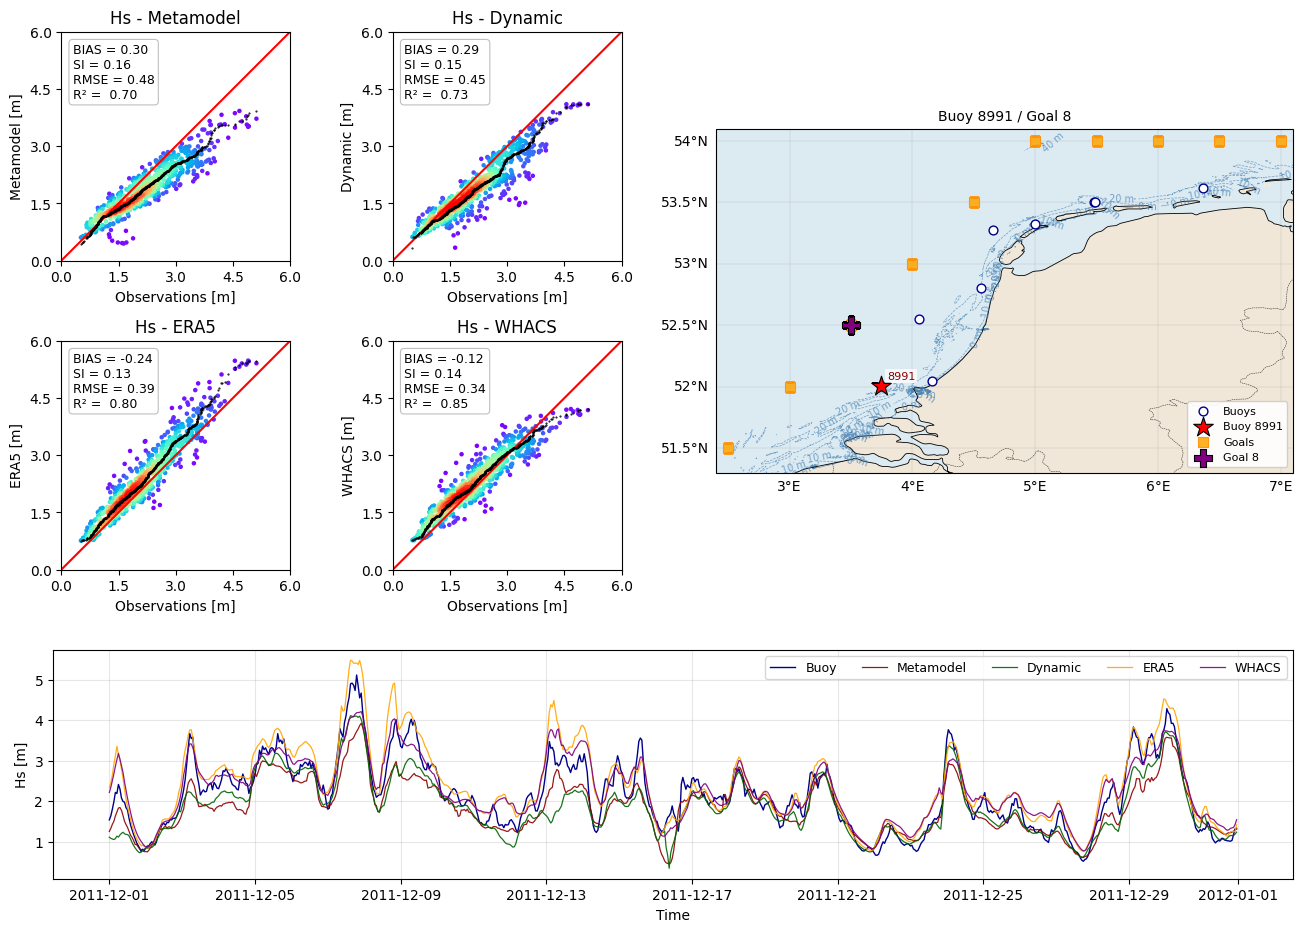

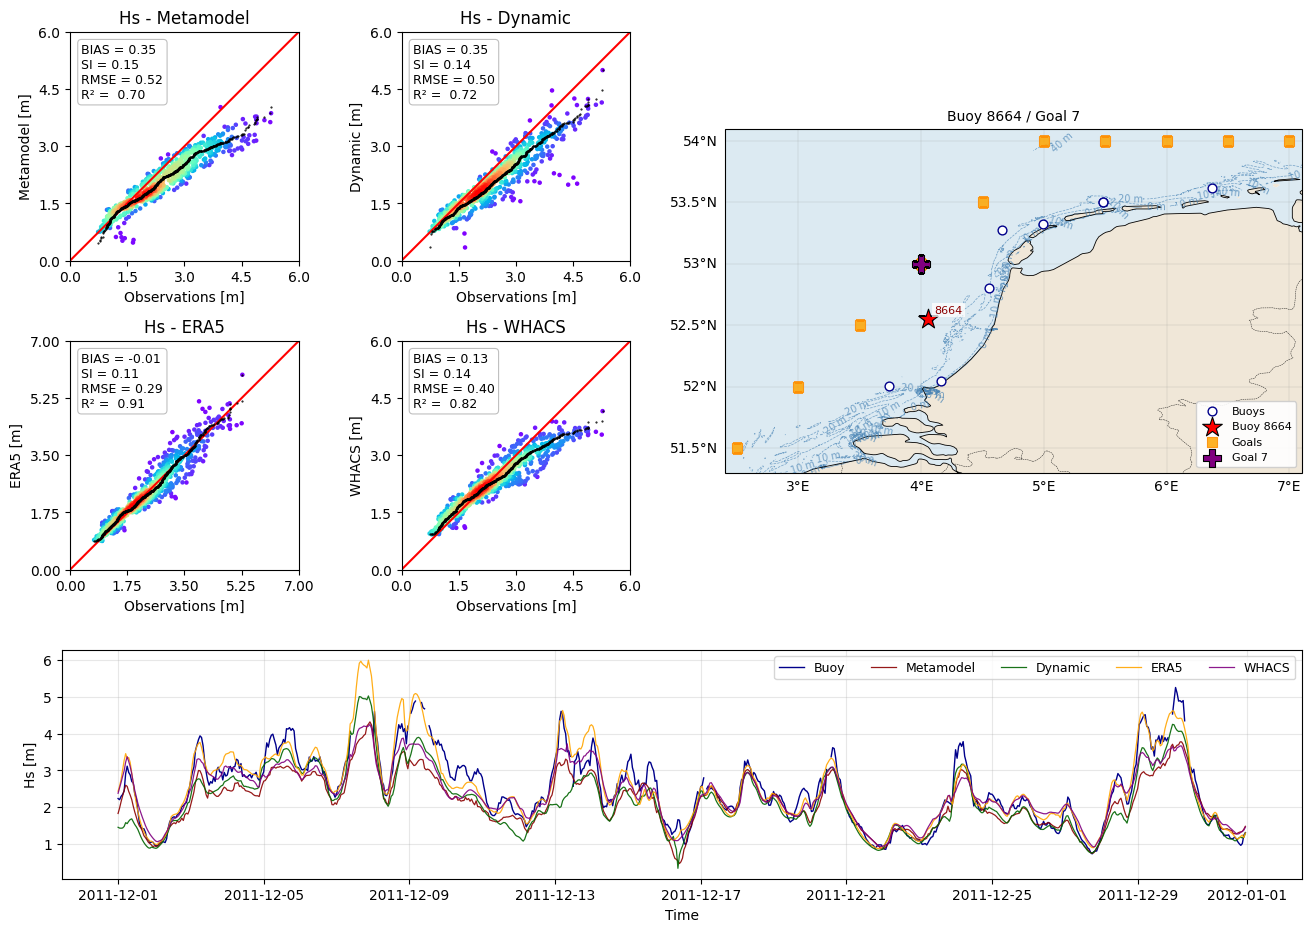

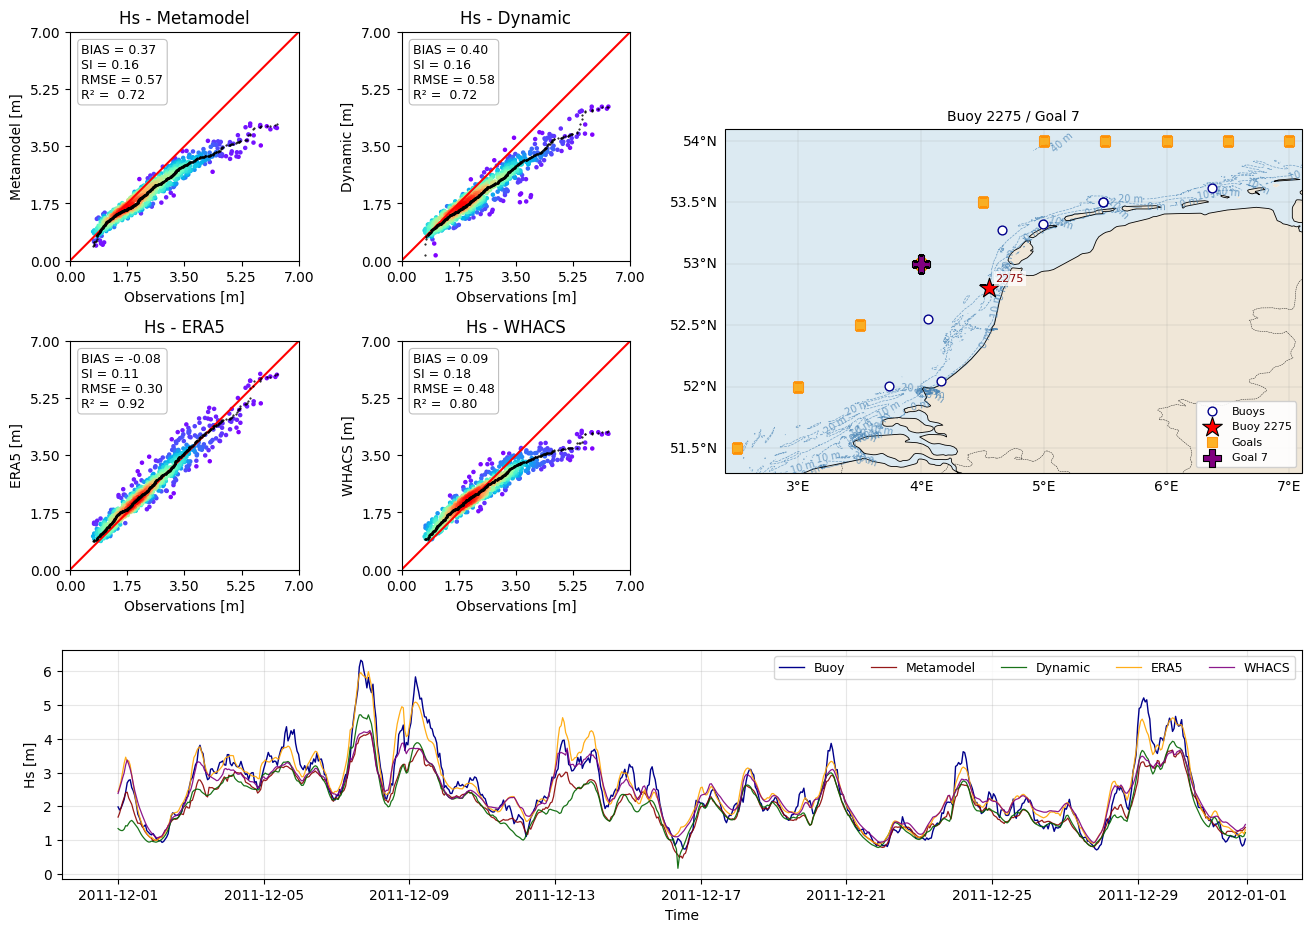

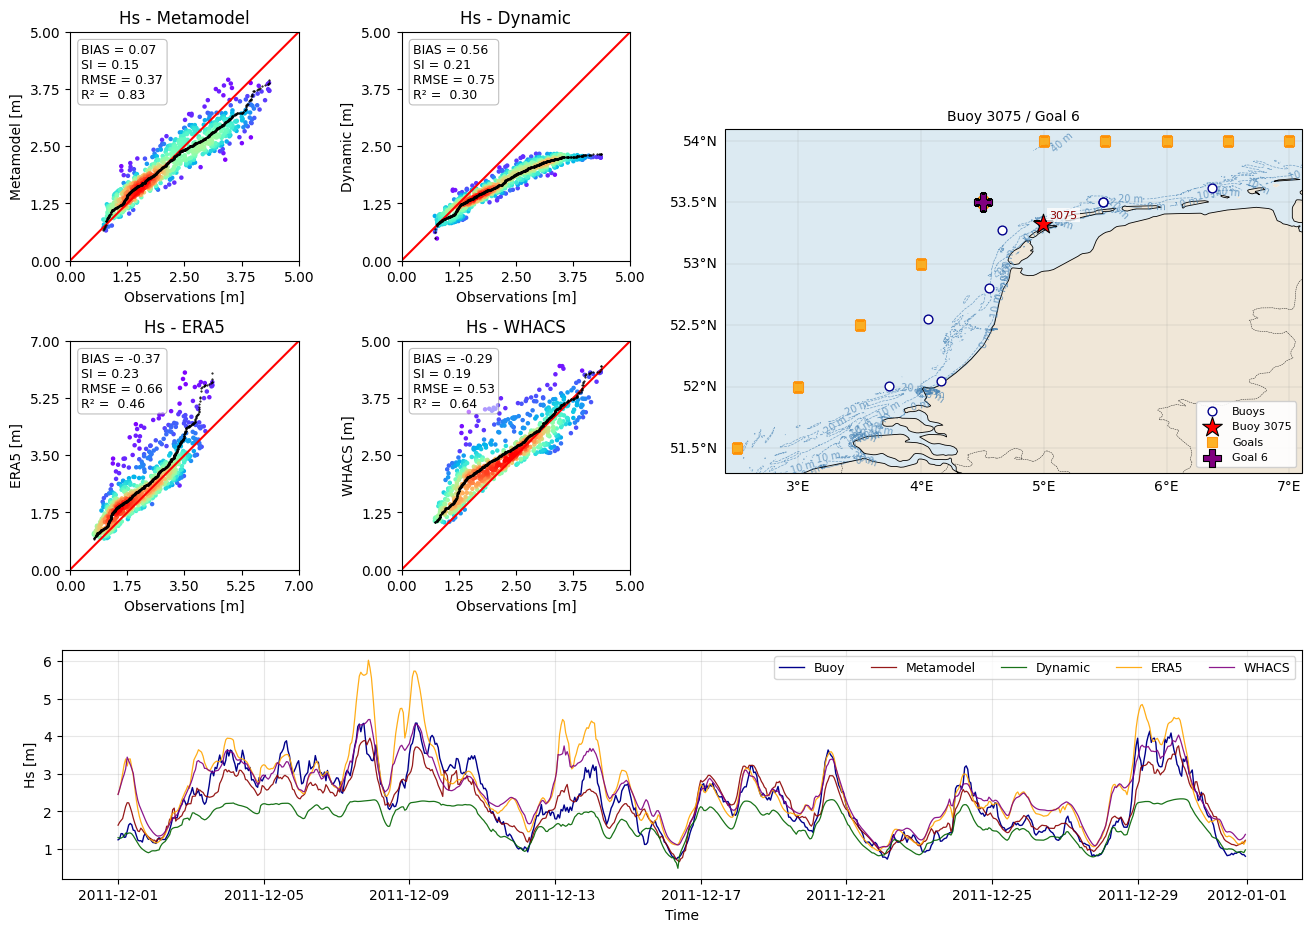

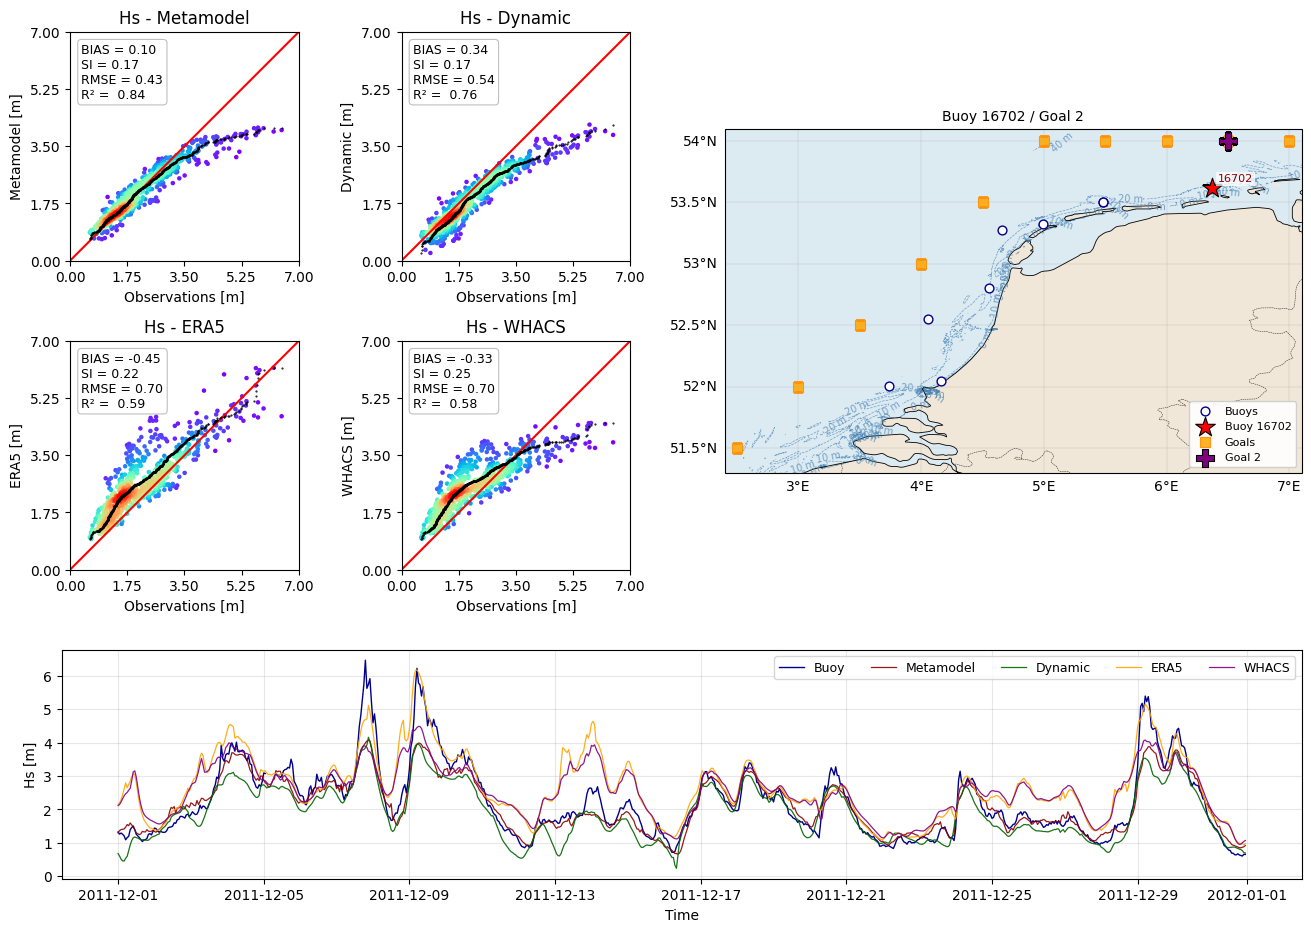

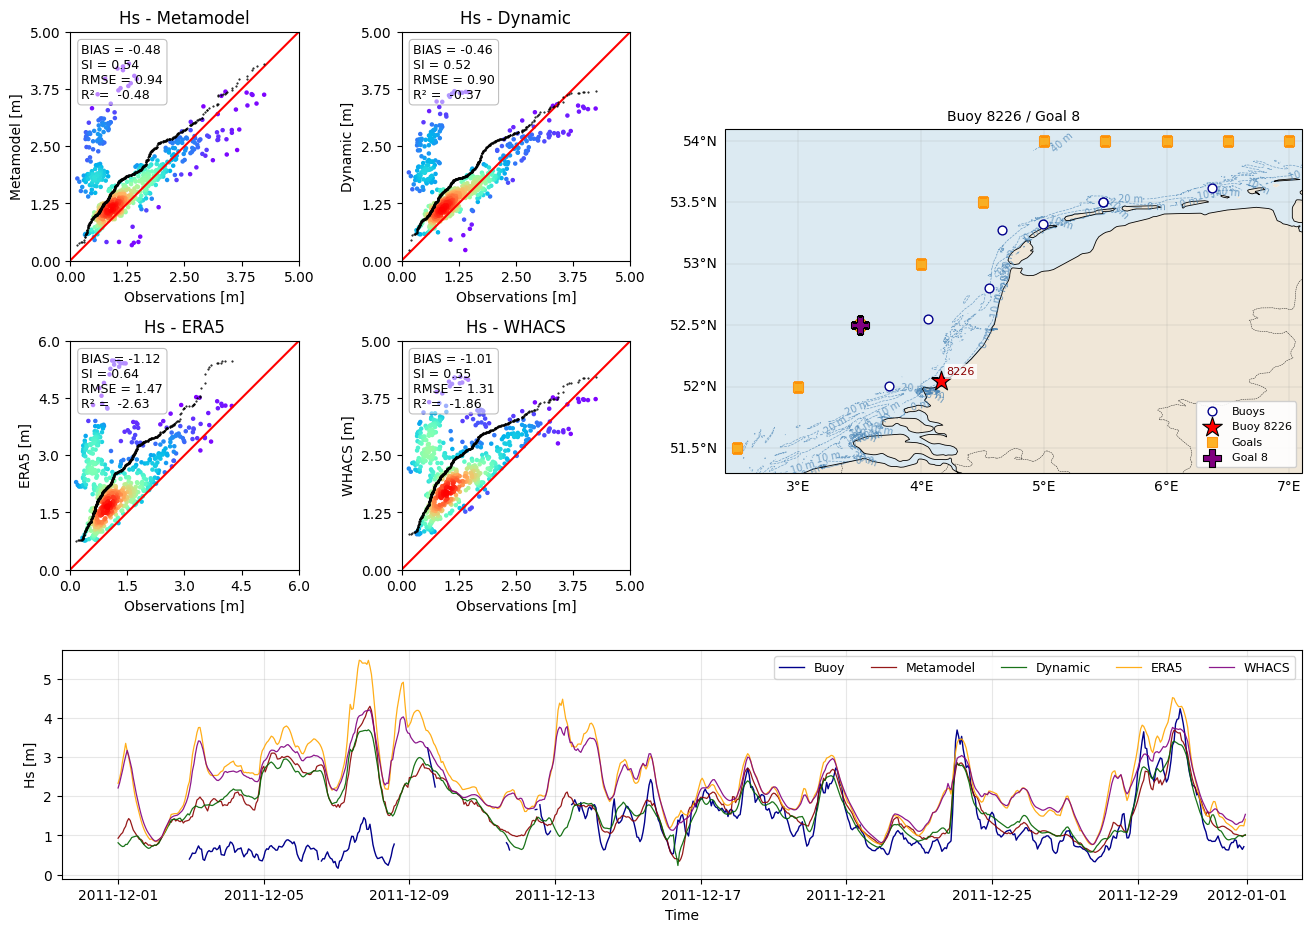

In [2]:
from utils.validation import validate_all_models

for i_buoy, (buoy, closest_goal) in enumerate(
    zip(observation_data.buoy, observation_data.closest_goal)
):
    validate_all_models(
        observation_data.sel(buoy=buoy),
        metamodel_data.isel(site=i_buoy),
        dynamic_data.isel(stations=i_buoy),
        era5_data.sel(goal=closest_goal),
        whacs_data.sel(goal=closest_goal),
        buoys=buoys_coords,
        goals=goals_coords,
        # extra_points=[
        #     {"df": codec_coords, "label": "CODEC", "color": "green", "marker": "D"},
        # ],
        bathymetry_path=BATHY_PATH,
    )

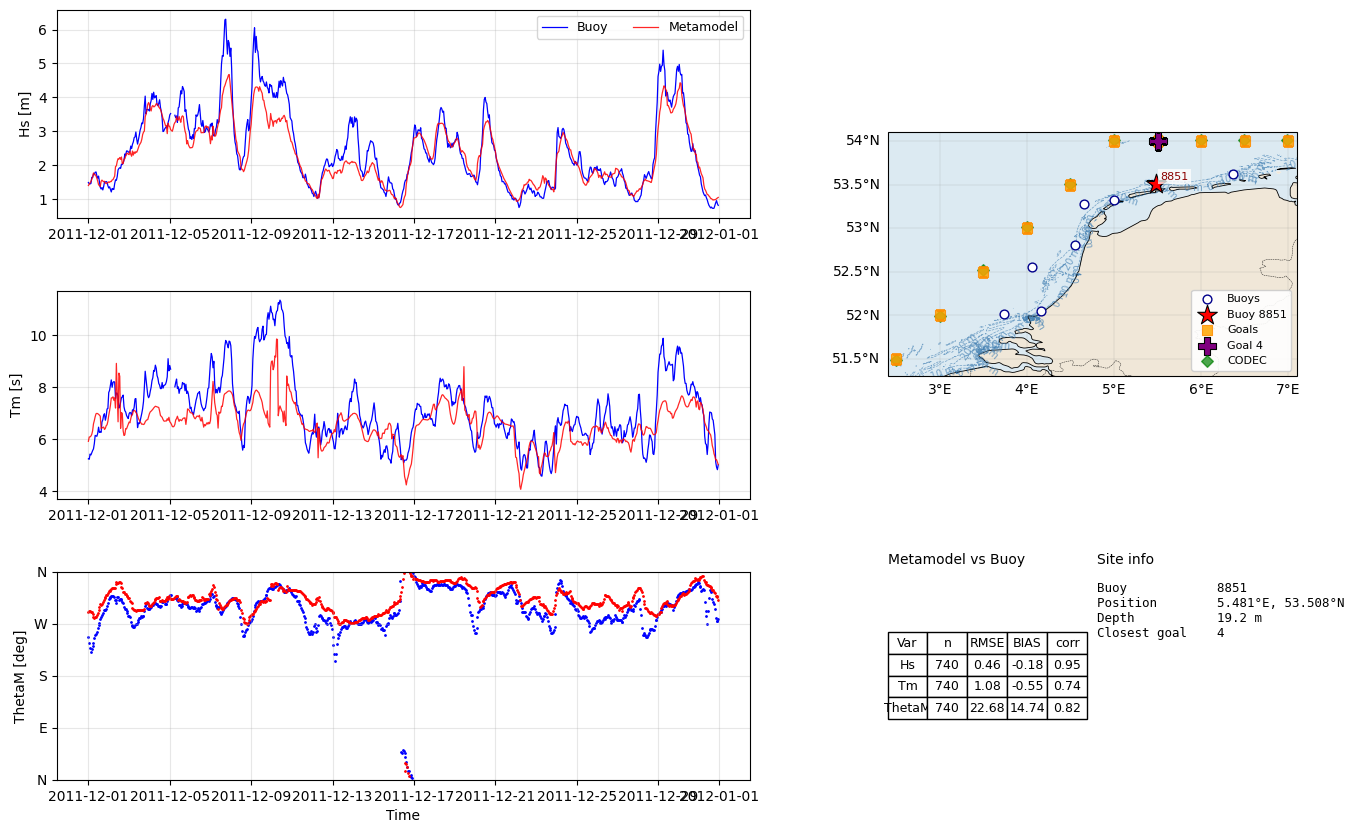

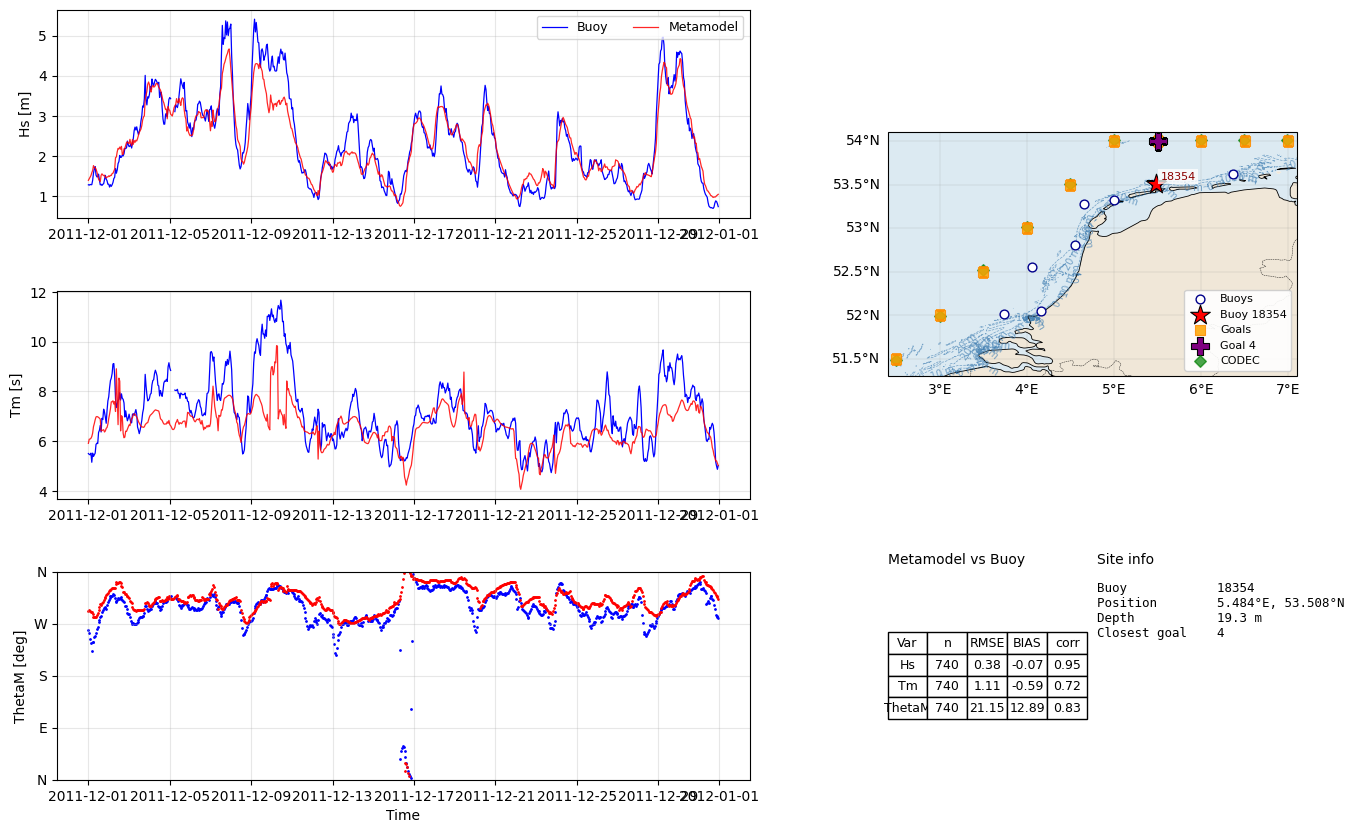

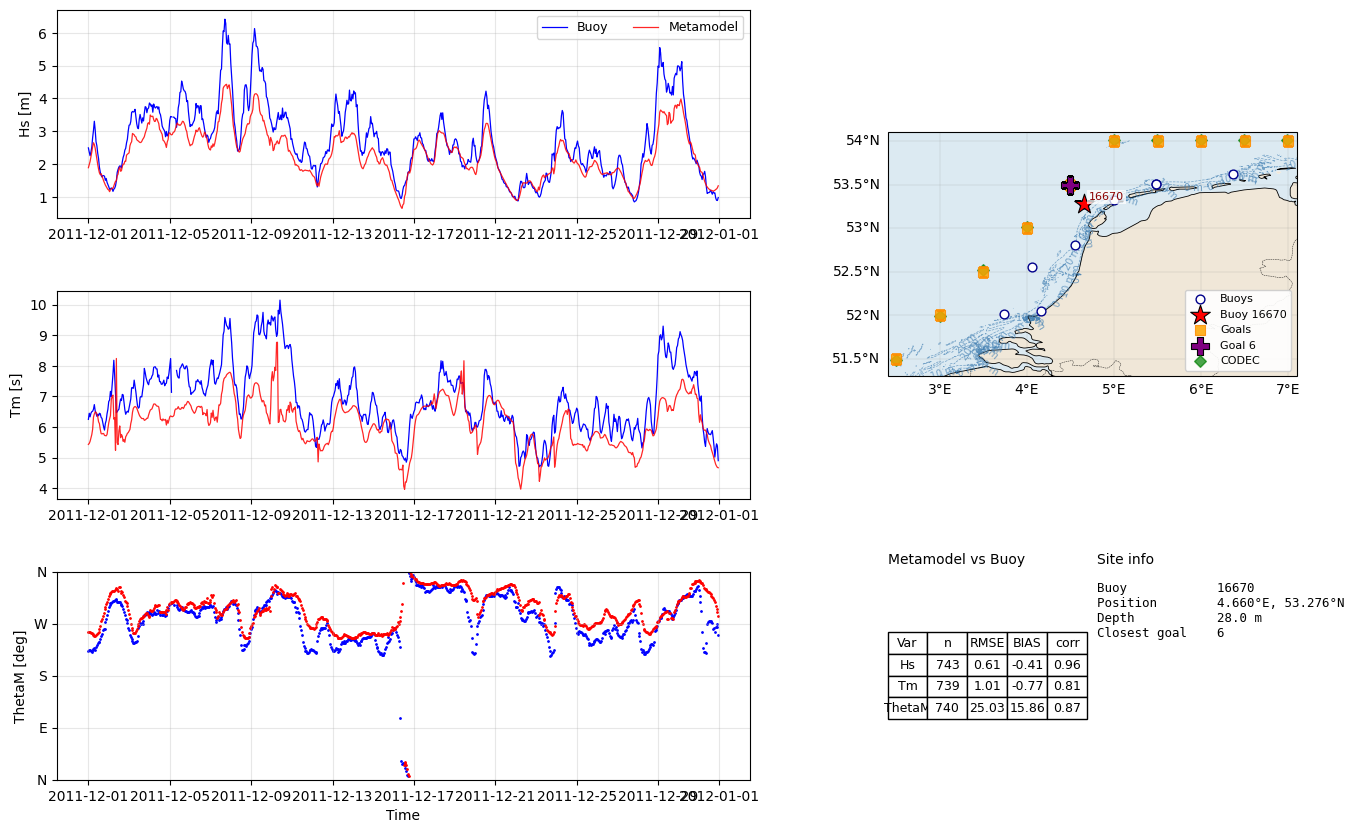

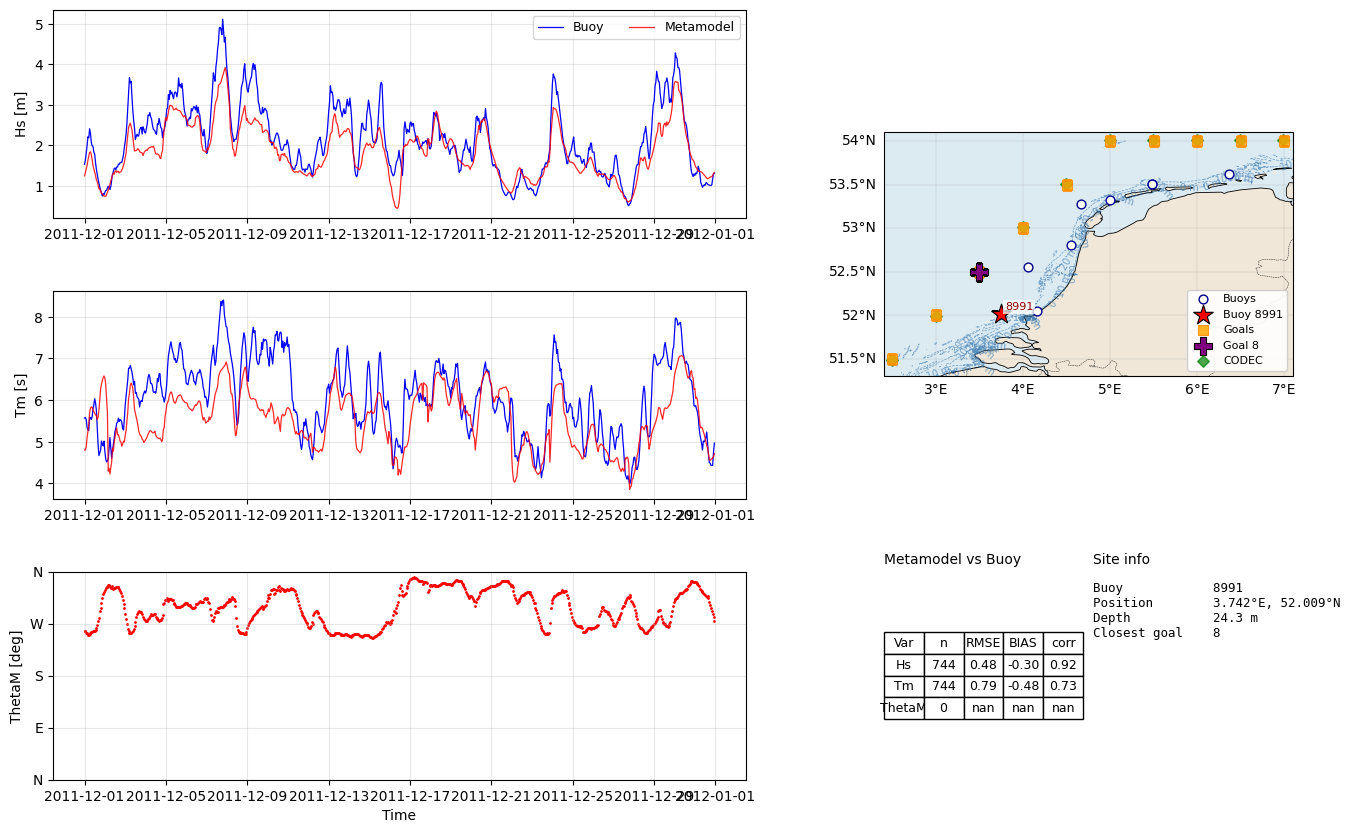

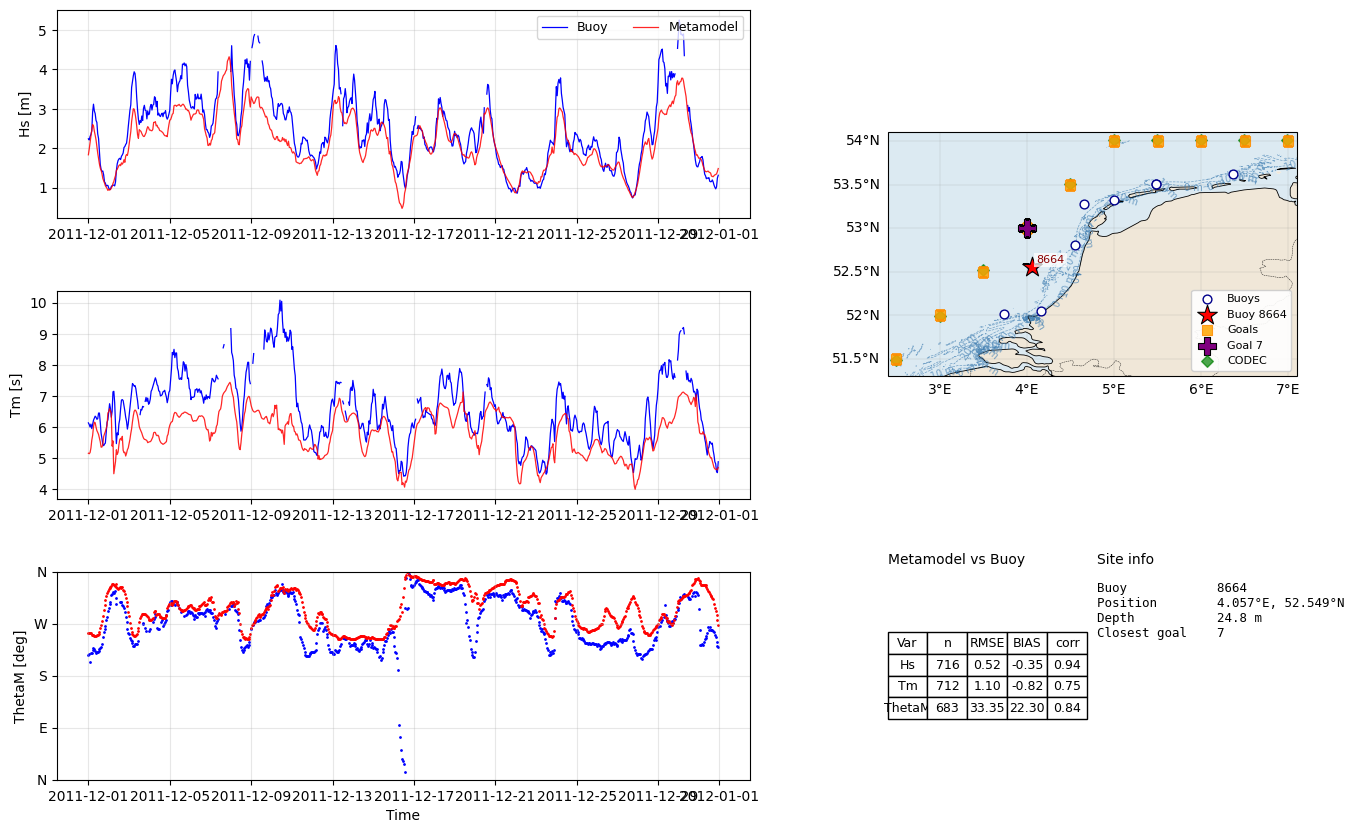

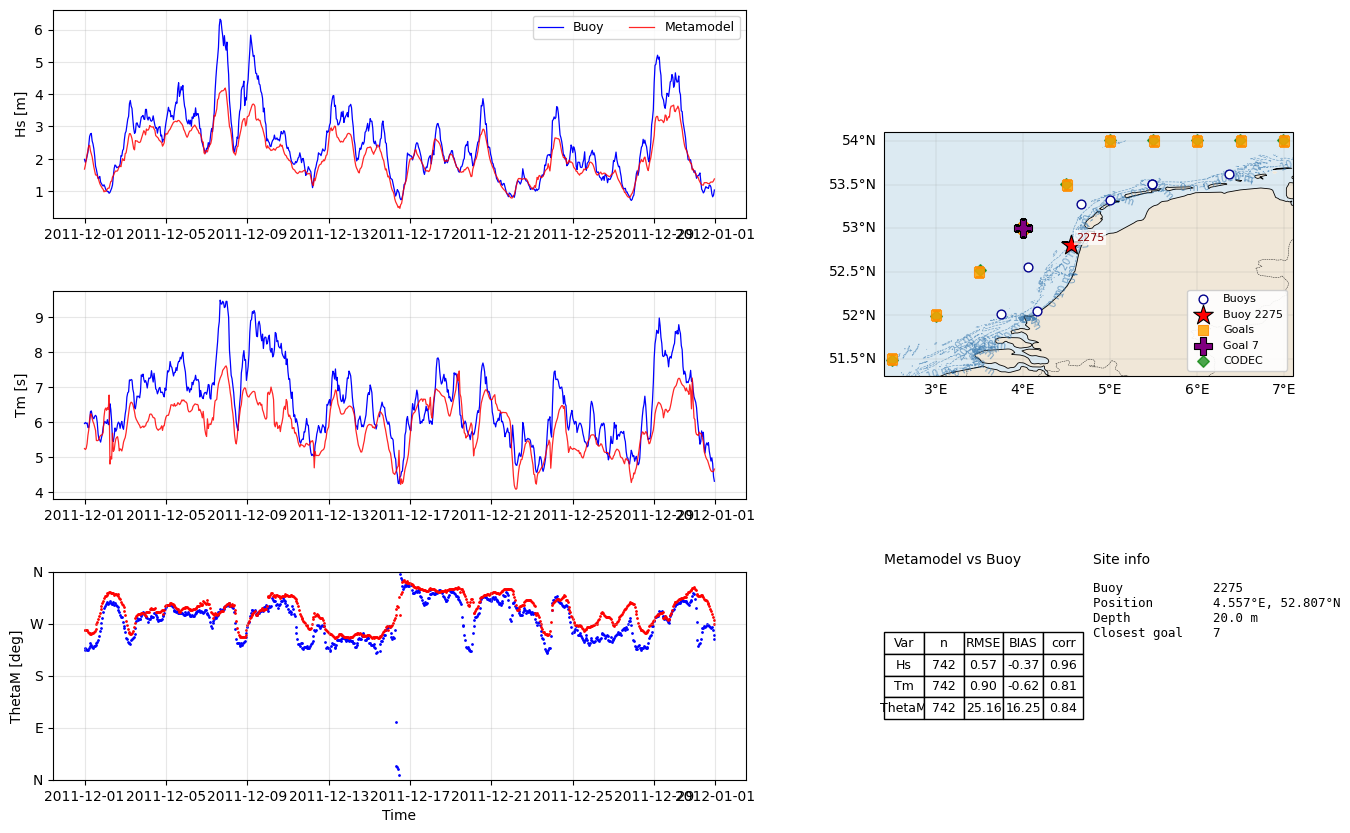

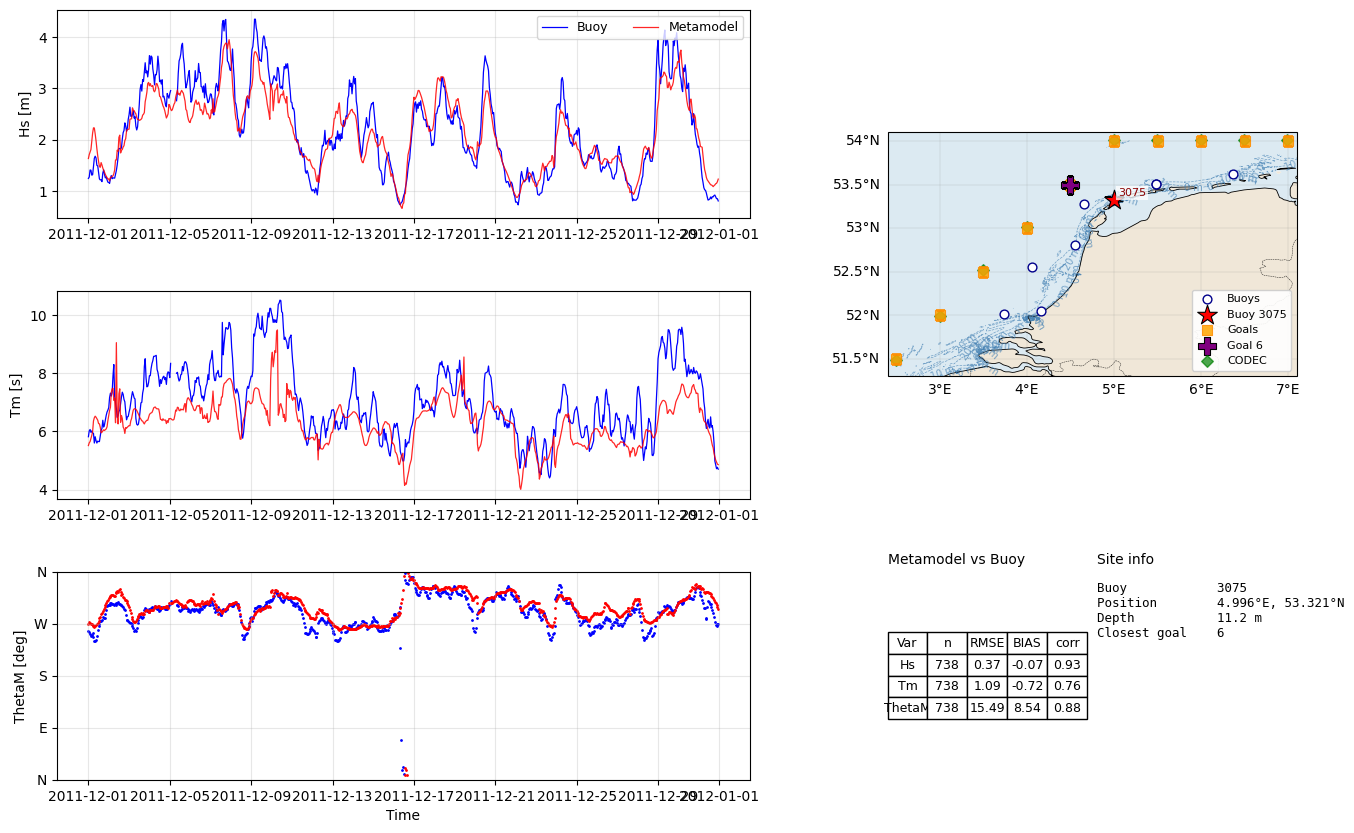

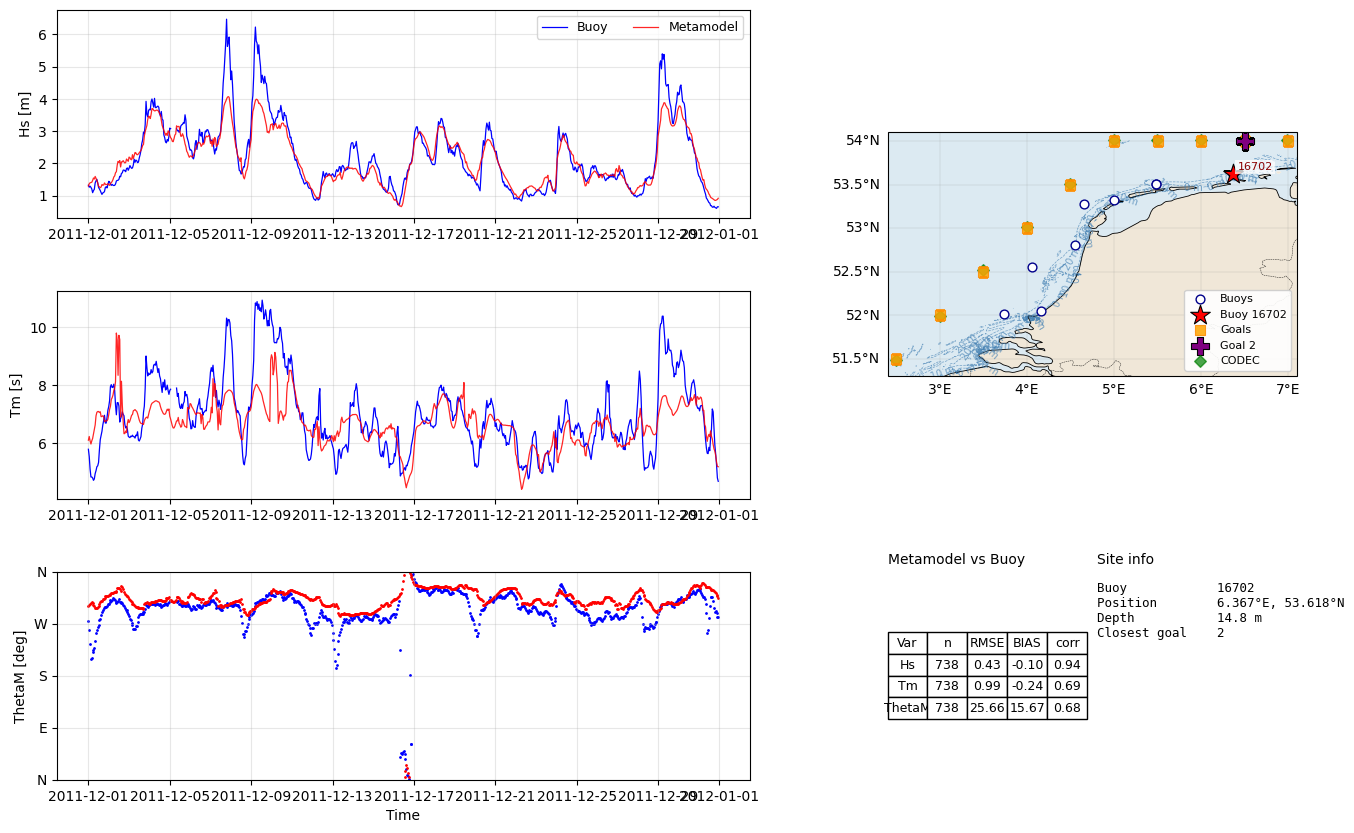

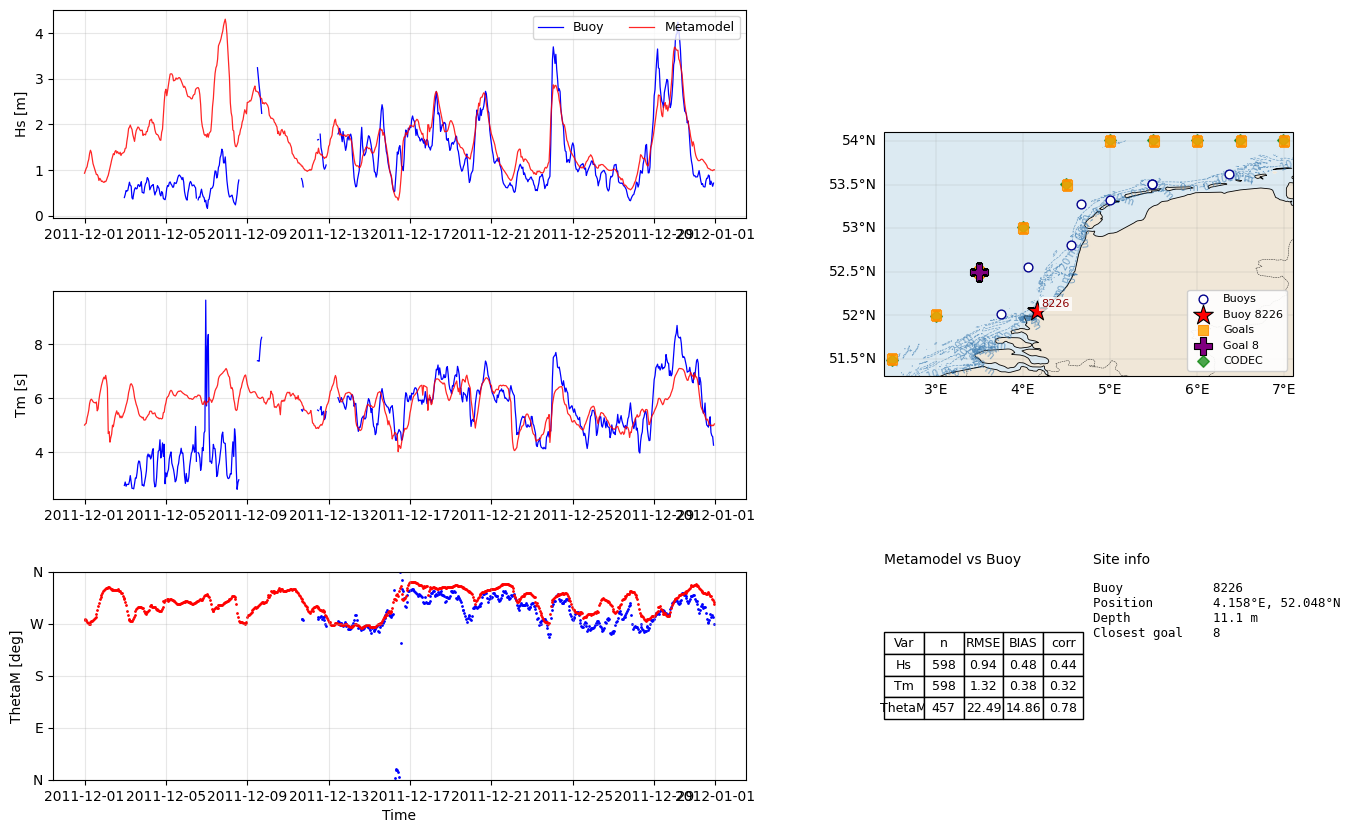

In [3]:
from utils.validation import DEFAULT_VAR_MAP, plot_series_validation_with_map

for i_buoy, (buoy, closest_goal) in enumerate(
    zip(observation_data.buoy, observation_data.closest_goal)
):
    obs_one = observation_data.sel(buoy=buoy)
    plot_series_validation_with_map(
        obs_one,
        metamodel_data.isel(site=i_buoy),
        DEFAULT_VAR_MAP["observation"],
        DEFAULT_VAR_MAP["metamodel"],
        label_a="Buoy",
        label_b="Metamodel",
        buoys=buoys_coords,
        goals=goals_coords,
        extra_points=[
            {"df": codec_coords, "label": "CODEC", "color": "green", "marker": "D"},
        ],
        bathymetry_path=BATHY_PATH,
        observation_data=obs_one,
    )